## Centreline fréchet distance matrices

In [ ]:
# main imports 

import yaml
import numpy as np
import matplotlib.pyplot as plt
from stl import mesh
from matplotlib.gridspec import GridSpec

# local imports
from pc_centrelines.frechet_dist import frdist
from pc_centrelines.utils import parametrise_ct, trim_adjust

## Data preparation

In [ ]:
conduit_map = {
    1:"straight_cyl",
    2:"straight_elp",
    3: "wavy",
    4:"rough",
    5:"sinu_1",
    6:"sinu_2",
    7:"branching",
    8:"archamps",
    9:"motiers",
    10:"faux_monnayeurs",
    11:"predjamski",
    12:"lauiloch"
    }


In [ ]:
# list all lbc centrelines, the sources and the target points
list_lbc_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    lbc_ct_fp = f"../data/{conduit_id}_{conduit_name}/lbc/{conduit_name}_centreline.txt"
    lbc_ct = np.loadtxt(lbc_ct_fp)
    P1 = lbc_ct[0]
    P2 = lbc_ct[-1]

    list_lbc_ct.append((lbc_ct, P1, P2))

FileNotFoundError: ../data/1_straight_cyl/lbc/straight_cyl_centreline.txt not found.

In [ ]:
# list all voxelised centrelines, the sources and the target points
list_mst_ct = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    delta = 100
    
    mst_ct_fp = f"../temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-simplified.txt"
    
    try: 
        mst_ct = np.loadtxt(mst_ct_fp)
    except FileNotFoundError:
        mst_ct = np.loadtxt(f"../temp/{conduit_id}_{conduit_name}/mst/{conduit_name}_{delta}_centerspline-direct.txt")
    P1 = mst_ct[0]
    P2 = mst_ct[-1]

    list_mst_ct.append((mst_ct, P1, P2))

In [7]:
# list all iterative centrelines, the sources and the target points
list_iter_ct = []
list_iter_norm = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    iter_ct_fp = f"../temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_centreline.txt"
    iter_norm_fp = f"../temp/{conduit_id}_{conduit_name}/iterative/{conduit_name}_vectors.txt"

    iter_ct = np.loadtxt(iter_ct_fp)
    iter_norm = np.loadtxt(iter_norm_fp)
    P1 = iter_ct[0]
    P2 = iter_ct[-1]

    list_iter_ct.append((iter_ct, P1, P2))
    list_iter_norm.append(iter_norm)

In [8]:
# list hydraulic centrelines, sources and target points. 
## plot the hydraulic centrelines. 
list_hydraulic_ct = []

for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    hydraulic_ct_fp = f"../temp/{conduit_id}_{conduit_name}/hydraulic/uniform_rescaled.csv"
    hydraulic_ct_fp2 = f"../temp/{conduit_id}_{conduit_name}/hydraulic/flux_rescaled.csv"

    hydraulic_ct1 = np.loadtxt(hydraulic_ct_fp, skiprows =0, delimiter=" ") 
    hydraulic_ct2 = np.loadtxt(hydraulic_ct_fp2, skiprows =0, delimiter=" ") 

    P1 = hydraulic_ct2[0]
    P2 = hydraulic_ct2[-1]

    list_hydraulic_ct.append((hydraulic_ct1, P1, P2, hydraulic_ct2))

In [9]:
list_theory_ct = []

N = 250

ct123 = np.vstack([np.linspace(-5, 5, N), np.zeros(N), np.zeros(N)]).T
ct4 = np.vstack([np.linspace(-4, 4, N), np.zeros(N), np.zeros(N)]).T
thetai = np.linspace(-np.pi, -np.pi/N, int(N/2))
thetaib = np.linspace(-(N-1)/N*np.pi, 0, int(N/2))

ct5a = np.vstack([np.cos(thetai)*2.5 - 2.5, -np.sin(thetai)*2.5, np.zeros(int(N/2))]).T
ct5b = np.vstack([np.cos(thetaib)*2.5 + 2.5, np.sin(thetaib)*2.5, np.zeros(int(N/2))]).T
ct5 = np.vstack([ct5a, ct5b])
ct6 = ct5.copy()
ct6[:, 1] *=2



ct123_vec = np.zeros((N,3))
ct123_vec[:, 0] = 1

ct4_vec = np.zeros((N,3))
ct4_vec[:, 0] = 1

ct5_vec = np.zeros((N, 3))
ct5_vec[:int(N/2), 0] = -np.sin(thetai) 
ct5_vec[int(N/2):, 0] = -np.sin(thetaib)
ct5_vec[:int(N/2), 1] = -np.cos(thetai)
ct5_vec[int(N/2):, 1] = np.cos(thetaib)

ct5_vec /= np.expand_dims(np.linalg.norm(ct5_vec, axis =1), -1)

ct6_vec = np.zeros((N, 3))
ct6_vec[:int(N/2), 0] = -np.sin(thetai) 
ct6_vec[int(N/2):, 0] = -np.sin(thetaib)
ct6_vec[:int(N/2), 1] = -2*np.cos(thetai)
ct6_vec[int(N/2):, 1] = 2*np.cos(thetaib)

ct6_vec /= np.expand_dims(np.linalg.norm(ct6_vec, axis =1), -1)

ct7 = 2*ct123
ct7_vec = ct123_vec.copy()



list_theory_ct.append([ct123, ct123[0], ct123[-1],ct123_vec])
list_theory_ct.append([ct123, ct123[0], ct123[-1],ct123_vec])
list_theory_ct.append([ct123, ct123[0], ct123[-1],ct123_vec])
list_theory_ct.append([ct4, ct4[0], ct4[-1],ct4_vec])
list_theory_ct.append([ct5, ct5[0], ct5[-1],ct5_vec])
list_theory_ct.append([ct6, ct6[0], ct6[-1],ct6_vec])
list_theory_ct.append([ct7, ct7[0], ct7[-1],ct7_vec])


## length and tortuosities for each centreline 

In [10]:
ct_lists = [list_theory_ct,
            list_lbc_ct,
            list_mst_ct,
            list_iter_ct,
            list_hydraulic_ct]

In [ ]:
results = np.ones((10, 12))*-999

for j, ct_list in enumerate(ct_lists):
    cts = [elem[0] for elem in ct_list]

    for i, ct in enumerate(cts):
        L = np.linalg.norm(ct[-1] - ct[0])

        l = np.cumsum(np.linalg.norm(np.diff(ct, axis = 0), axis=1))[-1]

        results[2*j,i] = l
        results[2*j+1, i] = l / L

Chord length: 10.00
Arc length: 10.00 
Chord length: 10.00
Arc length: 10.00 
Chord length: 10.00
Arc length: 10.00 
Chord length: 8.00
Arc length: 8.00 
Chord length: 10.00
Arc length: 15.71 
Chord length: 10.00
Arc length: 24.22 
Chord length: 20.00
Arc length: 20.00 
Chord length: 7.57
Arc length: 7.57 
Chord length: 7.85
Arc length: 7.85 
Chord length: 7.75
Arc length: 7.75 
Chord length: 5.82
Arc length: 5.83 
Chord length: 10.52
Arc length: 13.85 
Chord length: 10.45
Arc length: 23.15 
Chord length: 17.53
Arc length: 18.12 
Chord length: 38.26
Arc length: 38.49 
Chord length: 43.06
Arc length: 43.34 
Chord length: 77.66
Arc length: 78.80 
Chord length: 49.24
Arc length: 51.81 
Chord length: 30.53
Arc length: 59.79 
Chord length: 9.99
Arc length: 9.99 
Chord length: 9.99
Arc length: 10.01 
Chord length: 10.00
Arc length: 10.00 
Chord length: 8.00
Arc length: 8.05 
Chord length: 9.80
Arc length: 14.52 
Chord length: 9.87
Arc length: 22.69 
Chord length: 20.00
Arc length: 20.00 
Cho

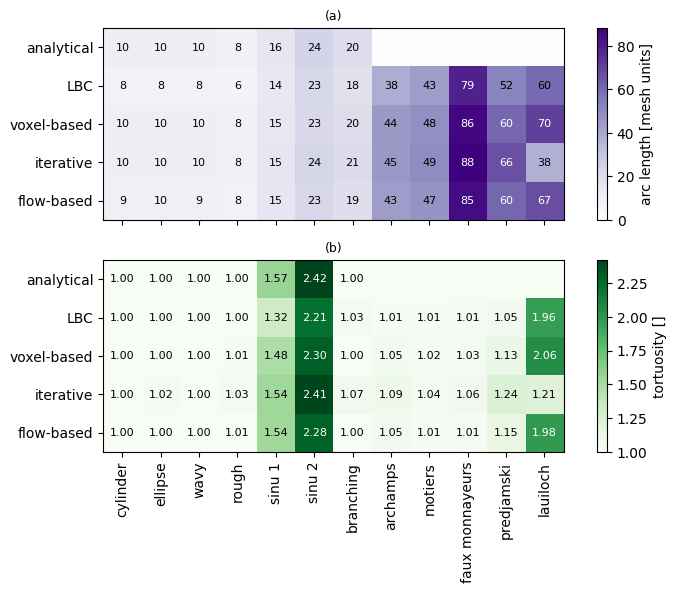

In [12]:
fig, axes = plt.subplots(2, 1, figsize = (8, 6), sharex=True)
im = axes[0].imshow(results[::2], cmap = "Purples", vmin = 0)

for j, row in enumerate(results[::2]):
    for i, elem in enumerate(row):
        color = "k"
        if elem > 60:
            color = "white"
        if elem >= 0:

            axes[0].text(i,j, f"{elem:.0f}", fontsize = 8, va = "center", ha="center", color =color)

cax = plt.colorbar(im)
cax.set_label("arc length [mesh units]")

im2 = axes[1].imshow(results[1::2], cmap = "Greens", vmin = 1)
cax2 = plt.colorbar(im2)
cax2.set_label("tortuosity []")

for j, row in enumerate(results[1::2]):
    for i, elem in enumerate(row):
        color = "k"
        if elem > 1.8:
            color = "white"
        if elem >= 0:

            axes[1].text(i,j, f"{elem:.2f}", fontsize = 8, va = "center", ha="center", color =color)

xlabels = ["cylinder", "ellipse", "wavy", "rough", "sinu 1", "sinu 2", "branching", "archamps", "motiers", "faux monnayeurs", "predjamski", "lauiloch"]
ylabels = ["analytical", "LBC", "voxel-based", "iterative", "flow-based"]

ax = axes[0]
ax.set_xticks(np.arange(0, 12))
ax.set_yticks([0,1,2,3,4])
ax.set_title("(a)", fontsize = 9)
ax.set_yticklabels(ylabels)
ax = axes[1]
ax.set_title("(b)", fontsize = 9)

ax.set_xticklabels(xlabels, rotation = 90)
ax.set_yticks([0,1,2,3,4])
ax.set_yticklabels(ylabels)
plt.tight_layout()
plt.savefig("../temp/figures/summary_length_tortuosity.png", dpi = 300)
plt.savefig("../temp/figures/summary_length_tortuosity.pdf")
plt.show()

We define here the usual plotting arguments by reading them from the plot_kwargs configuration file

In [13]:
with open(f"../notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
ct_1_kwargs = p["ct1_kwargs"]
ct_2_kwargs = p["ct2_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

## map of hydraulic centrelines and their differences

In [20]:
# list all meshes. 
list_meshes = []
list_meshes_fp = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    mesh_fp = f"../data/{conduit_id}_{conduit_name}/{conduit_name}.stl"
    list_meshes.append(mesh.Mesh.from_file(mesh_fp))
    list_meshes_fp.append(mesh_fp)

C:\Users\tangr\AppData\Local\Temp\ipykernel_4052\2734507559.py:51: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()


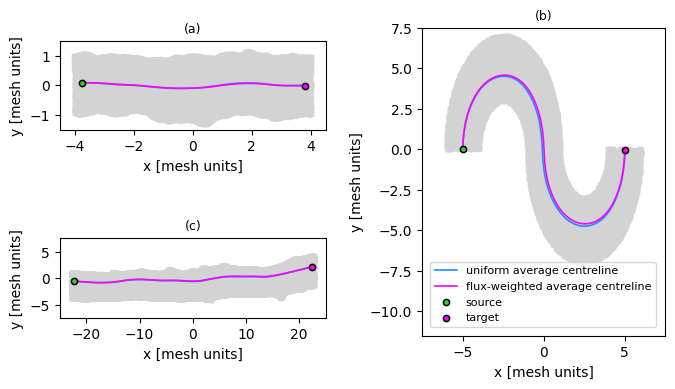

In [23]:
fig = plt.figure( figsize = (8, 5))

gs = GridSpec(nrows=100, ncols=100)

# plan view of rough passage. 
ax = fig.add_subplot(gs[:50, :43])
ax.scatter(*list_meshes[3][::50, [0, 1]].T,  **mesh_kwargs)
ax.plot(*list_hydraulic_ct[3][0][:, [0, 1]].T, **ct_2_kwargs, label ="uniform average centreline")
ax.plot(*list_hydraulic_ct[3][-1][:, [0, 1]].T, **ct_1_kwargs, label ="flux-weighted average centreline")
ax.scatter(*list_hydraulic_ct[3][-1][0, [0, 1]], **start_kwargs)
ax.scatter(*list_hydraulic_ct[3][-1][-1, [0, 1]], **end_kwargs)

ax.set_aspect("equal")
ax.set_xlabel("x [mesh units]")
ax.set_ylabel("y [mesh units]")
ax.set_xlim(-4.51, 4.51)
ax.set_ylim(-1.5, 1.5)
ax.set_title("(a)", fontsize = 9)

# plan view of highly sinuous passage. 
ax = fig.add_subplot(gs[10:-10,56:])
ax.scatter(*list_meshes[5][::50, [0, 1]].T,  **mesh_kwargs)
ax.plot(*list_hydraulic_ct[5][0][:, [0, 1]].T, **ct_2_kwargs, label ="uniform average centreline")
ax.plot(*list_hydraulic_ct[5][-1][:, [0, 1]].T, **ct_1_kwargs, label ="flux-weighted average centreline")
ax.set_title("(b)", fontsize = 9)
ax.scatter(*list_hydraulic_ct[5][-1][0, [0, 1]], **start_kwargs)
ax.scatter(*list_hydraulic_ct[5][-1][-1, [0, 1]], **end_kwargs)
ax.legend(loc = "lower left", bbox_to_anchor= (0.01, 0.01), fontsize = 8)

ax.set_aspect("equal")
ax.set_xlabel("x [mesh units]")
ax.set_ylabel("y [mesh units]")
ax.set_xlim(-7.51, 7.51)
ax.set_ylim(-11.51, 7.51)

# plan view of a real cave
ax = fig.add_subplot(gs[50:, :43])

ax.scatter(*list_meshes[8][::50, [0, 1]].T,  **mesh_kwargs)
ax.plot(*list_hydraulic_ct[8][0][:, [0, 1]].T, **ct_2_kwargs, label ="uniform average centreline")
ax.plot(*list_hydraulic_ct[8][-1][:, [0, 1]].T, **ct_1_kwargs, label ="flux-weighted average centreline")
ax.set_title("(c)", fontsize = 9)
ax.scatter(*list_hydraulic_ct[8][-1][0, [0, 1]], **start_kwargs)
ax.scatter(*list_hydraulic_ct[8][-1][-1, [0, 1]], **end_kwargs)

ax.set_aspect("equal")
ax.set_xlabel("x [mesh units]")
ax.set_ylabel("y [mesh units]")
ax.set_ylim(-7.51, 7.51)

plt.tight_layout()
plt.savefig("../temp/figures/demonstration-hydraulic.png", dpi = 300)
plt.savefig("../temp/figures/demonstration-hydraulic.pdf")
plt.show()

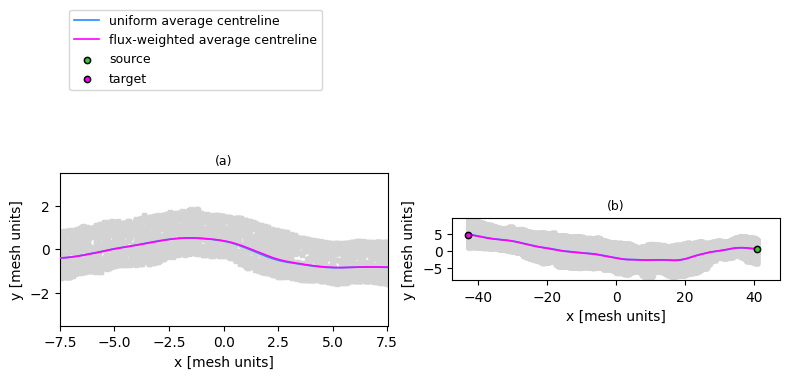

In [25]:
fig, axes = plt.subplots(1, 2, figsize = (8, 5))


# plan view of rough passage. 
ax = axes[0]
ax.scatter(*list_meshes[7][::50, [0, 1]].T,  **mesh_kwargs)
ax.plot(*list_hydraulic_ct[7][0][:, [0, 1]].T, **ct_2_kwargs, label ="uniform average centreline")
ax.plot(*list_hydraulic_ct[7][-1][:, [0, 1]].T, **ct_1_kwargs, label ="flux-weighted average centreline")
ax.scatter(*list_hydraulic_ct[7][-1][0, [0, 1]], **start_kwargs)
ax.scatter(*list_hydraulic_ct[7][-1][-1, [0, 1]], **end_kwargs)

ax.legend(loc = "lower left", bbox_to_anchor= (0.01, 1.5), fontsize = 9)
ax.set_aspect("equal")
ax.set_xlabel("x [mesh units]")
ax.set_ylabel("y [mesh units]")
ax.set_xlim(-7.51, 7.51)
ax.set_ylim(-3.5, 3.5)
ax.set_title("(a)", fontsize = 9)

# plan view of highly sinuous passage. 

ax = axes[1]
ax.scatter(*list_meshes[9][::50, [0, 1]].T,  **mesh_kwargs)
ax.plot(*list_hydraulic_ct[9][0][:, [0, 1]].T, **ct_2_kwargs, label ="uniform average centreline")
ax.plot(*list_hydraulic_ct[9][-1][:, [0, 1]].T, **ct_1_kwargs, label ="flux-weighted average centreline")
ax.set_title("(b)", fontsize = 9)
ax.scatter(*list_hydraulic_ct[9][-1][0, [0, 1]], **start_kwargs)
ax.scatter(*list_hydraulic_ct[9][-1][-1, [0, 1]], **end_kwargs)

ax.set_aspect("equal")
ax.set_xlabel("x [mesh units]")
ax.set_ylabel("y [mesh units]")
ax.set_xlim(-47.51, 47.51)

plt.tight_layout()
plt.savefig("../temp/figures/demonstration-hydraulic-real.png", dpi = 300)
plt.savefig("../temp/figures/demonstration-hydraulic-real.pdf")
plt.show()

In [26]:

print("LBC extremities")
LBC_extremities = []

for k in range(0, 7):
    P1_theory, P2_theory =  list_theory_ct[k][1], list_theory_ct[k][2]
    P1_lbc, P2_lbc  =  list_lbc_ct[k][1], list_lbc_ct[k][2]

    dist1 = np.minimum(np.linalg.norm(P1_theory-P1_lbc), np.linalg.norm(P2_theory-P1_lbc))
    which = np.argmin((np.linalg.norm(P1_theory-P1_lbc), np.linalg.norm(P2_theory-P1_lbc)))
    dist2 = [np.linalg.norm(P2_theory-P2_lbc), np.linalg.norm(P1_theory-P2_lbc)][which]

    LBC_extremities.append([dist1,dist2])

LBC_extremities = np.array(LBC_extremities)

print("MST extremities")
MST_extremities = []

for k in range(0, 7):
    P1_mst, P2_mst  =  list_mst_ct[k][1], list_mst_ct[k][2]
    P1_theory, P2_theory =  list_theory_ct[k][1], list_theory_ct[k][2]

    dist1 = np.minimum(np.linalg.norm(P1_theory-P1_mst), np.linalg.norm(P2_theory-P1_mst))
    which = np.argmin((np.linalg.norm(P1_theory-P1_mst), np.linalg.norm(P2_theory-P1_mst)))
    dist2 = [np.linalg.norm(P2_theory-P2_mst), np.linalg.norm(P1_theory-P2_mst)][which]
    MST_extremities.append([dist1,dist2])

MST_extremities = np.array(MST_extremities)

print("Iterative extremities")
iter_extremities = []

for k in range(0, 7):
    P1_iter, P2_iter  =  list_iter_ct[k][1], list_iter_ct[k][2]
    P1_theory, P2_theory =  list_theory_ct[k][1], list_theory_ct[k][2]

    dist1 = np.minimum(np.linalg.norm(P1_theory-P1_iter), np.linalg.norm(P2_theory-P1_iter))
    which = np.argmin((np.linalg.norm(P1_theory-P1_iter), np.linalg.norm(P2_theory-P1_iter)))
    dist2 = [np.linalg.norm(P2_theory-P2_iter), np.linalg.norm(P1_theory-P2_iter)][which]
    iter_extremities.append([dist1,dist2])


iter_extremities = np.array(iter_extremities)

print("hydraulic extremities")
hyd_extremities = []

for k in range(0, 7):
    P1_theory, P2_theory  =  list_theory_ct[k][1], list_theory_ct[k][2]
    P1_hyd, P2_hyd =  list_hydraulic_ct[k][1], list_hydraulic_ct[k][2]

    dist1 = np.minimum(np.linalg.norm(P1_theory-P1_hyd), np.linalg.norm(P2_theory-P1_hyd))
    which = np.argmin((np.linalg.norm(P1_theory-P1_hyd), np.linalg.norm(P2_theory-P1_hyd)))
    dist2 = [np.linalg.norm(P2_theory-P2_hyd), np.linalg.norm(P1_theory-P2_hyd)][which]
    hyd_extremities.append([dist1,dist2])

hyd_extremities = np.array(hyd_extremities)


LBC extremities
MST extremities
Iterative extremities
hydraulic extremities


In [27]:
extremities_distance = np.vstack([LBC_extremities.T, MST_extremities.T, iter_extremities.T, hyd_extremities.T])


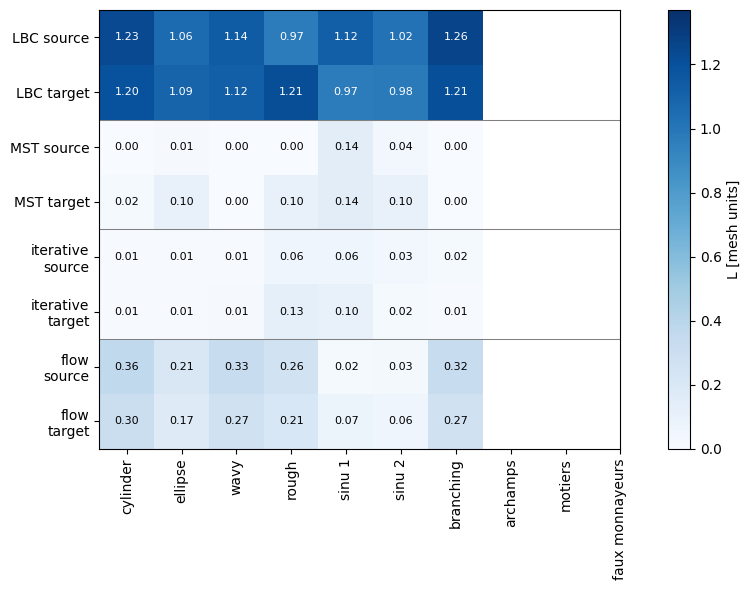

In [28]:
fig, ax = plt.subplots(figsize = (10, 6))

im = ax.imshow(extremities_distance, cmap = "Blues", vmin = 0, vmax=1.37)
xlabels = ["cylinder", "ellipse", "wavy", "rough", "sinu 1", "sinu 2", "branching", "archamps", "motiers", "faux monnayeurs"]
ylabels = ["LBC source", "LBC target", "MST source", "MST target", "iterative\nsource", "iterative\ntarget","flow\nsource", "flow\ntarget",]


ax.set_xticks([0,1,2,3,4,5,6,7,8,9])
ax.set_xticklabels(xlabels, rotation = 90)
ax.set_yticks([0,1,2,3,4,5, 6,7])
ax.set_yticklabels(ylabels)


for j, row in enumerate(extremities_distance):
    for i, elem in enumerate(row):
        color = "k"
        if elem > .7:
            color = "white"
        if elem >= 0:

            ax.text(i,j, f"{elem:.2f}", fontsize = 8, va = "center", ha="center", color =color)

ax.set_aspect("equal")
ax.axhline(3.5, color = "grey", lw = 0.75)
ax.axhline(1.5, color = "grey", lw = 0.75)
ax.axhline(5.5, color = "grey", lw = 0.75)

ax.set_ylim(7.5, -0.5)
cax = plt.colorbar(im)
cax.set_label("L [mesh units]")
plt.tight_layout()
plt.savefig("../temp/figures/distance_to_extremities.png", dpi = 300)
plt.savefig("../temp/figures/distance_to_extremities.pdf")


## Fréchet pitfalls. Flip, Clip, Parametrise.

When calculating the discrete Frechet metric, we try to find the infemum of any coupling between two nodes of a polyline. Ideally, all our centrelines would begin at the same start point and finish at the same end point. But it is not the case for the hydraulic lines. The discrete frechet metric would be dominated by this discrepancy. 

Another thing to bear in mind is the order of parametrisation of our polylines.

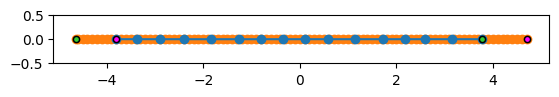

In [29]:
fig, ax = plt.subplots()

# hydraulic centreline 1
# lbc centreline 1. 
hyd_ct1 = list_hydraulic_ct[0][0]
lbc_ct1 = list_lbc_ct[0][0]

ax.plot(*lbc_ct1[:, [0,1]].T, "-o")
ax.plot(*hyd_ct1[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1[-1, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Here the start and end of our lines are reversed, so the discrete frechet metric is quite large. 
We would have to take the minimum of the two. Also, we have to be careful of the recursion depth in checking the coupling distances. 
The hydraulic centreline is very densely sampled, perhaps too densely. We could resample it to a step of 0.1 and calculate the frechet metric then. 

In [30]:
parametrise_ct(hyd_ct1, 2)

array([[-4.64007303e+00, -7.68627296e-04, -5.50514299e-04],
       [-2.30535416e+00, -5.08013070e-04, -5.47551277e-04],
       [ 2.93647002e-02, -1.79322223e-04, -5.32102718e-04],
       [ 2.36408356e+00,  1.33794512e-04, -5.24094324e-04],
       [ 4.69880242e+00,  4.74069175e-04, -5.51718629e-04]])

In [31]:
# naive calculation using near identical lines, but parametrised in opposite directions, under
# condition of monotonic increasing parametrisation.
frdist(parametrise_ct(hyd_ct1[::-50], 2), lbc_ct1)

np.float64(3.5028677778009625)

In [32]:
list_hydraulic_ct[0][0]

array([[-4.64007303e+00, -7.68627296e-04, -5.50514299e-04],
       [-4.60007784e+00, -7.60514930e-04, -5.49947684e-04],
       [-4.50008988e+00, -7.46343282e-04, -5.48043873e-04],
       [-4.40010191e+00, -7.33176091e-04, -5.48263972e-04],
       [-4.30011395e+00, -7.20386739e-04, -5.48018712e-04],
       [-4.20012598e+00, -7.09567610e-04, -5.44957592e-04],
       [-4.10013802e+00, -6.98006094e-04, -5.44049384e-04],
       [-4.00015005e+00, -6.87094737e-04, -5.44355835e-04],
       [-3.90016208e+00, -6.78260317e-04, -5.42385212e-04],
       [-3.80017412e+00, -6.70710311e-04, -5.37999447e-04],
       [-3.70018615e+00, -6.60927182e-04, -5.35315864e-04],
       [-3.60019819e+00, -6.49771981e-04, -5.33859468e-04],
       [-3.50021022e+00, -6.38400670e-04, -5.34800654e-04],
       [-3.40022225e+00, -6.29630279e-04, -5.37689263e-04],
       [-3.30023429e+00, -6.22546285e-04, -5.38834578e-04],
       [-3.20024632e+00, -6.13500531e-04, -5.40321849e-04],
       [-3.10025835e+00, -6.03619730e-04

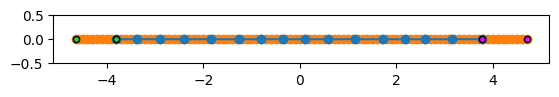

In [35]:
fig, ax = plt.subplots()

# hydraulic centreline 1
# lbc centreline 1. 
hyd_ct1 = list_hydraulic_ct[0][0]
lbc_ct1 = list_lbc_ct[0][0]

ax.plot(*lbc_ct1[:, [0,1]].T, "-o")
ax.plot(*parametrise_ct(hyd_ct1[::2], 0.1)[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1[-1, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1[0, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Intuitively in this example, the discrete frechet distance metric between these two parallel lines should be near equal to the maximum of the distance between the start points or end points.

In [36]:
frdist(parametrise_ct(hyd_ct1[::2], 0.1), lbc_ct1[::-1])

np.float64(0.9303449952082539)

We can check this is the case: 

In [37]:
print("distance between start points: ", np.linalg.norm(lbc_ct1[-1] - hyd_ct1[0]))
print("distance between end points: ", np.linalg.norm(lbc_ct1[0] - hyd_ct1[-1]))

distance between start points:  0.8366101649619704
distance between end points:  0.9303449952082539


Trimming: we may have to use the best of both worlds... 

In [38]:
hyd_ct1_t, lbc_ct1_t = trim_adjust(hyd_ct1, lbc_ct1, 0.1)

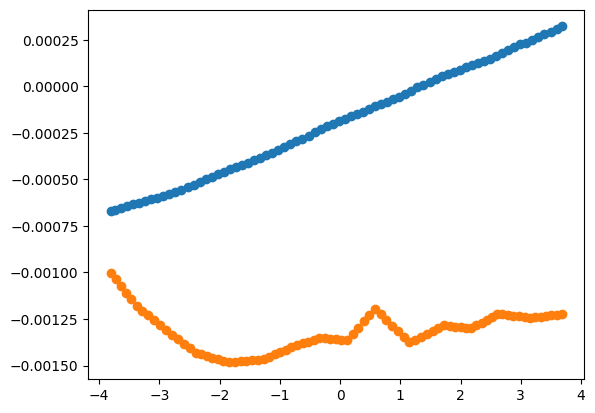

In [42]:
plt.plot(*hyd_ct1_t[:,[0,1]].T, "-o")
plt.plot(*lbc_ct1_t[:,[0,1]].T, "-o")

Therefore, we have to trim the frechet metric calculation to the portions of centreline that overlap. 

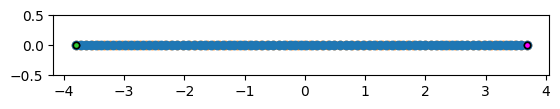

In [43]:
fig, ax = plt.subplots()

ax.plot(*lbc_ct1_t[:, [0,1]].T, "-o")
ax.plot(*hyd_ct1_t[:, [0,1]].T, "-o", zorder = -10)
ax.scatter(*lbc_ct1_t[0, [0,1]], **start_kwargs)
ax.scatter(*hyd_ct1_t[0, [0,1]], **start_kwargs)
ax.scatter(*lbc_ct1_t[-1, [0,1]], **end_kwargs)
ax.scatter(*hyd_ct1_t[-1, [0,1]], **end_kwargs)
ax.set_aspect("equal")
ax.set_ylim(-0.5, 0.5)
plt.show()

Now that the two centrelines overlap, the discrete frechet metric is dominated by the largest spacing between two nodes of each centreline. If one is densely sampled, and the other not, then the discrete frechet metric describes the larger of the two sampling intervals. 

Clearly, we need at least to sample each polyline densely. The more dense the sampling, the closer we may approach the actual frechet distance between the two curves. 

In [ ]:
def prepare_frechet(list1, list2, eps):
    """run the flip, trim, resample routine on all pairs of centreline
    before computing the discrete fréchet metric at a given epsilon
    """
    
    clean_list1 = []
    clean_list2 = []
    # parametrise, clip, flip.
    for ct1, ct2 in zip(list1, list2):
        k1 = np.maximum(1, np.floor(eps / np.mean(np.linalg.norm(np.diff(ct1, axis =0), axis=1))))
        k2 = np.maximum(1, np.floor(eps / np.mean(np.linalg.norm(np.diff(ct2, axis =0), axis=1))))
        ct1_t, ct2_t = trim_adjust(ct1[::int(k1)], ct2[::int(k2)], eps)
        
        clean_list1.append(ct1_t)
        clean_list2.append(ct2_t)
    
    return clean_list1, clean_list2

In [ ]:
# comparison between all two possible combinations. (2 choose 5)
theory_to_lbc = prepare_frechet([elem[0] for elem in list_theory_ct], [elem[0] for elem in list_lbc_ct], 0.1)
theory_to_mst = prepare_frechet([elem[0] for elem in list_theory_ct], [elem[0] for elem in list_mst_ct], 0.1)
theory_to_iter = prepare_frechet([elem[0] for elem in list_theory_ct], [elem[0] for elem in list_iter_ct], 0.1)
theory_to_hyd2 = prepare_frechet([elem[0] for elem in list_theory_ct], [elem[3] for elem in list_hydraulic_ct], 0.1)

hyd2_to_lbc = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_lbc_ct], 0.1)
hyd2_to_mst = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_mst_ct], 0.1)
hyd2_to_iter = prepare_frechet([elem[3] for elem in list_hydraulic_ct], [elem[0] for elem in list_iter_ct], 0.1)

iter_to_lbc = prepare_frechet([elem[0] for elem in list_lbc_ct], [elem[0] for elem in list_iter_ct], 0.1)
iter_to_mst = prepare_frechet([elem[0] for elem in list_mst_ct], [elem[0] for elem in list_iter_ct], 0.1)

mst_to_lbc = prepare_frechet([elem[0] for elem in list_mst_ct], [elem[0] for elem in list_lbc_ct], 0.1)

2.0 1.0
2.0 1.0
2.0 1.0
3.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
2.0 1.0
2.0 1.0
2.0 1.0
3.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
2.0 1.0
2.0 1.0
2.0 1.0
3.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
2.0 1.0
2.0 1.0
2.0 1.0
3.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0
1.0 1.0


In [46]:
comparison_map = {0 : theory_to_lbc,
                  1 : theory_to_mst,
                  2 : theory_to_iter,
                  3 : theory_to_hyd2,
                  4 : hyd2_to_lbc,
                  5 : hyd2_to_mst, 
                  6 : hyd2_to_iter,
                  7 : mst_to_lbc, 
                  8 : iter_to_lbc,
                  9 : iter_to_mst}

In [47]:
fr_results_hydraulic = -np.ones((10,12))

In [48]:
for i, (ct1, ct2) in enumerate(zip(*theory_to_lbc)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[0, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*theory_to_mst)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[1, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*theory_to_iter)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[2, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*theory_to_hyd2)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[3, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*hyd2_to_lbc)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[4, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*hyd2_to_mst)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[5, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*hyd2_to_iter)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[6, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*mst_to_lbc)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[7, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*iter_to_lbc)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[8, i] = thedist 
for i, (ct1, ct2) in enumerate(zip(*iter_to_mst)):
    thedist = frdist(ct1, ct2)
    L = np.cumsum(np.linalg.norm(np.diff(ct2, axis = 0), axis=1))[-1]
    fr_results_hydraulic[9, i] = thedist 

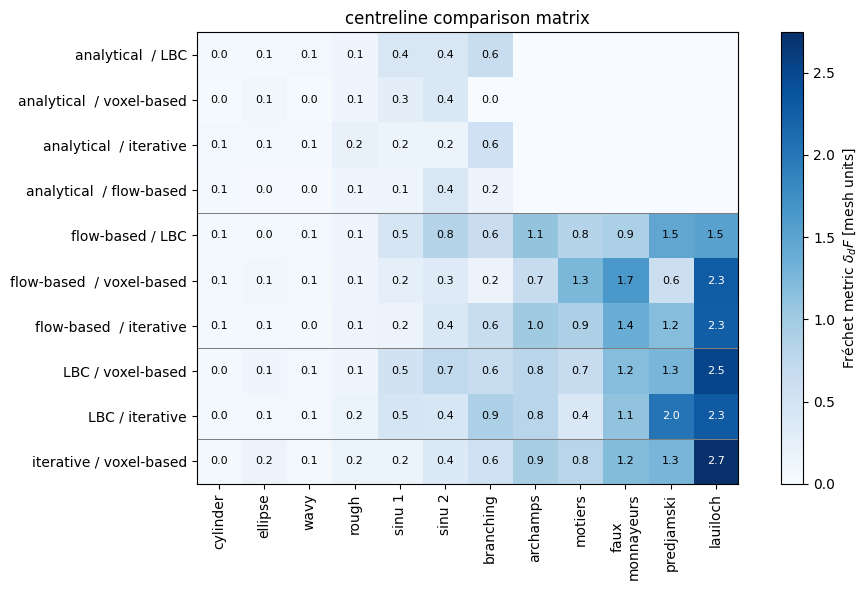

In [49]:
xlabels = ["cylinder", "ellipse", "wavy", "rough", "sinu 1", "sinu 2", "branching", "archamps","motiers", "faux\nmonnayeurs", "predjamski", "lauiloch"]
ylabels = ["analytical  / LBC", "analytical  / voxel-based", "analytical  / iterative", "analytical  / flow-based", "flow-based / LBC",  "flow-based  / voxel-based", "flow-based  / iterative",  "LBC / voxel-based", "LBC / iterative", "iterative / voxel-based"]

fig, ax = plt.subplots(figsize = (10,6))

im = ax.imshow(fr_results_hydraulic, cmap = "Blues", vmin=0)
ax.set_xticks([0,1,2,3,4,5,6,7,8,9, 10,11])
ax.set_yticks([0,1,2,3,4,5,6,7,8,9])

for j, row in enumerate(fr_results_hydraulic):
    for i, elem in enumerate(row):
        color = "k"
        if elem > 1.8:
            color = "white"
        if elem > 0:

            ax.text(i,j, f"{elem:.1f}", fontsize = 8, va = "center", ha="center", color =color)
ax.set_xticklabels(xlabels, rotation =90)
ax.set_yticklabels(ylabels)
cax = plt.colorbar(im)
cax.set_label("Fréchet metric $\\delta_dF$ [mesh units]")
ax.set_title("centreline comparison matrix")

ax.axhline(3.5, lw = 0.75, color = "grey")
ax.axhline(6.5, lw = 0.75, color = "grey")
ax.axhline(8.5, lw = 0.75, color = "grey")
plt.tight_layout()

plt.savefig("../temp/figures/comparison_matrix.pdf")
plt.savefig("../temp/figures/comparison_matrix.png", dpi= 300)

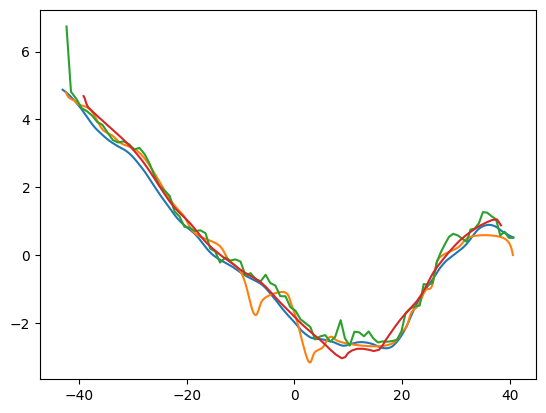

In [54]:
plt.plot(*list_hydraulic_ct[9][0][:, [0, 1]].T)
plt.plot(*list_mst_ct[9][0][:, [0, 1]].T)
plt.plot(*list_iter_ct[9][0][:, [0, 1]].T)
plt.plot(*list_lbc_ct[9][0][:, [0, 1]].T)

In [55]:
# list all meshes. 
list_meshes = []
for k, (conduit_id, conduit_name) in enumerate(conduit_map.items()):
    mesh_fp = f"../data/{conduit_id}_{conduit_name}/{conduit_name}.stl"
    list_meshes.append(mesh.Mesh.from_file(mesh_fp))

In [56]:
def plot_compare(comp_list, comp_id, conduit,labels, ylim=0.5,zlim=0.5,  figsize = (8,8), theloc="lower left", thebbox=(0.02, 1.02)):
    fig, axes = plt.subplots(2,1, figsize = figsize)
    ax = axes[0]
    ax.plot(*comp_list[0][conduit][:, [0,1]].T, "-o", markersize =2, lw = 0.5, label = labels[0])
    ax.plot(*comp_list[1][conduit][:, [0,1]].T, "-o", zorder = -10,  markersize =2, lw = 0.5, label = labels[1])
    ax.scatter(*comp_list[0][conduit][0, [0,1]], **start_kwargs)
    ax.scatter(*comp_list[1][conduit][-1, [0,1]], **end_kwargs)

    ax.scatter(*list_meshes[conduit].centroids[::50, [0,1]].T, **mesh_kwargs)
    ax.set_aspect("equal")
    ax.set_ylim(-ylim, ylim)
    
    ax.set_title(f"normalised fréchet metric: {fr_results_hydraulic[comp_id, conduit]:.2f}", fontsize=9, loc = "right")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.legend(loc = theloc, bbox_to_anchor=thebbox)
    ax.scatter(*comp_list[0][conduit][-1, [0,1]], **end_kwargs)
    ax.scatter(*comp_list[1][conduit][0, [0,1]], **start_kwargs)

    ax = axes[1]
    ax.plot(*comp_list[0][conduit][:, [0,2]].T, "-o", markersize =2, lw = 0.5, label = labels[0])
    ax.plot(*comp_list[1][conduit][:, [0,2]].T, "-o", zorder = -10,  markersize =2, lw = 0.5, label = labels[1])
    ax.scatter(*comp_list[0][conduit][0, [0,2]], **start_kwargs)
    ax.scatter(*comp_list[1][conduit][-1, [0,2]], **end_kwargs)

    ax.scatter(*list_meshes[conduit].centroids[::50, [0,2]].T, **mesh_kwargs)
    ax.set_aspect("equal")
    ax.set_ylim(-zlim, zlim)
    
    ax.set_title(f"normalised fréchet metric: {fr_results_hydraulic[comp_id, conduit]:.2f}", fontsize=9, loc = "right")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("z [m]")
    ax.legend(loc = theloc, bbox_to_anchor=thebbox)
    ax.scatter(*comp_list[0][conduit][-1, [0,2]], **end_kwargs)
    ax.scatter(*comp_list[1][conduit][0, [0,2]], **start_kwargs)
    return fig, ax

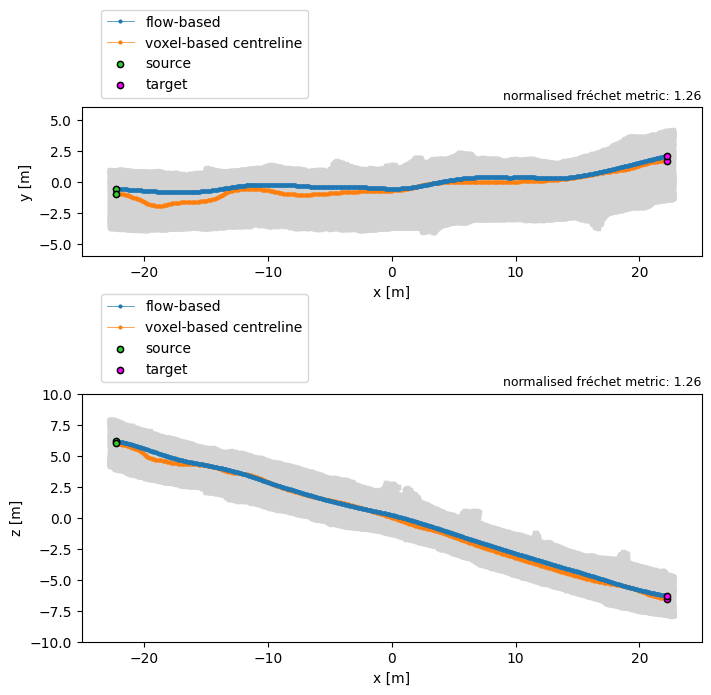

In [57]:
plot_compare(hyd2_to_mst, 5, 8, ("flow-based", "voxel-based centreline"),6, 10)
plt.savefig("../temp/figures/Motiers_comparison_iter_voxel.png", dpi =300)

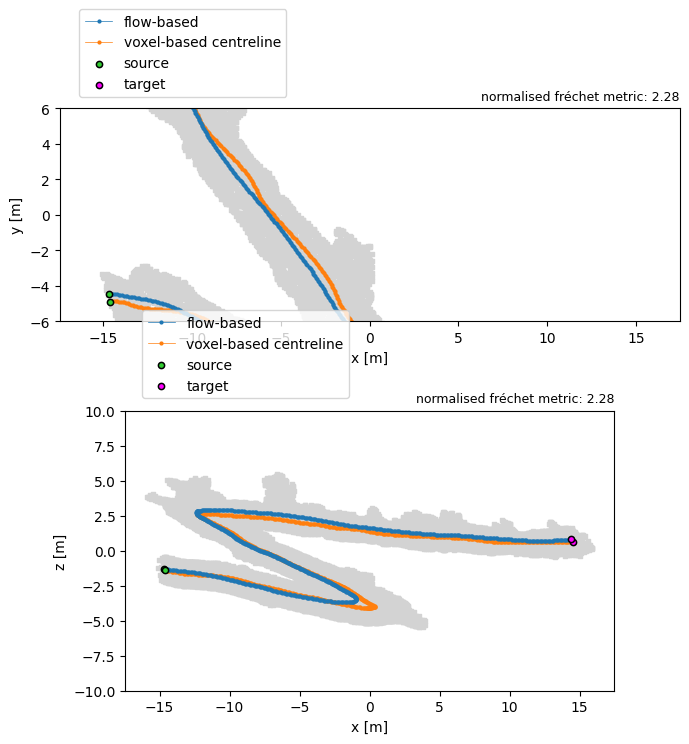

In [58]:
plot_compare(hyd2_to_mst, 5, 11, ("flow-based", "voxel-based centreline"),6, 10)
plt.savefig("../temp/figures/Lauiloch_comparison_iter_voxel.png", dpi =300)

In [ ]:
plot_compare(hyd2_to_iter, 6, 8, ("flow-based", "iterative walker"),6, 10)
plt.savefig("../temp/figures/Motiers_comparison_flow_iter.png", dpi =300)

In [ ]:
plot_compare(iter_to_mst,9, 11, ("iterative centreline", "voxel-based centreline"),6, 10)
plt.savefig("../temp/figures/Lauiloch_comparison_iter_voxel.png", dpi =300)

In [ ]:
plot_compare(mst_to_lbc,7, 5, ("voxel-based centreline", "LBC-derived centreline"),10, theloc="upper left", thebbox=(1.02,1))
plt.savefig("../temp/figures/Extrasinuous_comparison.png", dpi = 300)

In [ ]:
plot_compare(hyd2_to_lbc,4, 5, ("flow-weighted centreline", "LBC-derived centreline"), 10)
plt.savefig("../temp/figures/Sinuous_comparison.png")

In [ ]:
plot_compare(theory_to_hyd2,3, 5, ("analytical_centreline", "flow-based centreline"),10)
plt.savefig("../temp/figures/Extrasinuous_comparison3.png")

In [ ]:
plot_compare(hyd2_to_iter,6, 5, ("uniformly averaged centreline", "iterative centreline"),10)
plt.savefig("../temp/figures/Extrasinuous_comparison3.png")